# Abandono bancario: diagnóstico por segmentos

**Hector Americo Torres Huamani** · [Repositorio](https://github.com/hectortorres26/analisis-abandono-bancario)

## 1. Contexto y objetivo

Identificar segmentos con mayor proporción de abandono para orientar hipótesis de retención. El análisis describe asociaciones en una muestra educativa de clientes; no estima el efecto causal de una campaña ni construye un sistema de decisiones individuales.

## 2. Datos y reproducibilidad

[Bank Customer Churn Dataset, publicado por Gaurav Topre en Kaggle](https://www.kaggle.com/datasets/gauravtopre/bank-customer-churn-dataset). Descarga el archivo `Bank Customer Churn Prediction.csv` y colócalo en `data/`.

Los resultados publicados se ejecutaron con copias públicas descargadas de las fuentes indicadas. No se ha verificado identidad byte a byte con los archivos del Drive del autor. Las huellas SHA-256 en [data/README.md](data/README.md) y `reports/metrics.json` identifican las entradas exactas. Los datasets se excluyen de Git; consulta las condiciones de cada fuente antes de reutilizarlos o redistribuirlos.

| Campo | Uso |
|---|---|
| `customer_id` | Validación de unicidad; excluido del análisis |
| `churn` | Indicador de abandono: 1 = abandono, 0 = permanencia |
| `country`, `gender` | Segmentación categórica |
| `age`, `tenure` | Edad y antigüedad declaradas en el dataset |
| `products_number`, `credit_card`, `active_member` | Relación comercial; dos últimos indicadores binarios |
| `credit_score`, `balance`, `estimated_salary` | Perfil numérico; no se publican registros individuales |

Ejecuta desde la raíz del repositorio con el entorno de `requirements.txt`. El código de análisis reside en `src/analysis.py`, para que el cuaderno y la línea de comandos utilicen el mismo procedimiento.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from src.analysis import run

ROOT = Path.cwd()
assert (ROOT / 'src/analysis.py').exists(), 'Abre el cuaderno desde la raíz del repositorio.'

## 3. Diseño del análisis

1. Validar columnas, identificadores únicos, ausencia de nulos, valores binarios y dominios numéricos. Los errores detienen la ejecución en vez de modificar registros silenciosamente.
2. Retirar `customer_id` tras verificar la unicidad. No mostrar ni exportar filas individuales.
3. Calcular tasas por país, género, actividad, número de productos y grupos de edad (18–29, 30–39, 40–49, 50–59 y 60+).
4. Presentar denominadores e intervalos de Wilson del 95 %. Suprimir grupos con menos de 30 observaciones.
5. Calcular correlaciones de las variables numéricas originales, incluida la variable de abandono, sin correlacionar una matriz de correlaciones.

In [2]:
resultado = run(ROOT / 'data/Bank Customer Churn Prediction.csv', ROOT / 'reports')

## 4. Resultados calculados

Las tablas siguientes proceden de esta ejecución. Las métricas comparativas utilizan una prueba reservada cuando el proyecto entrena modelos.

In [3]:
display(pd.DataFrame([{'Clientes': resultado['n_clientes'], 'Abandonos': resultado['abandonos'], 'Tasa': resultado['tasa_abandono'], 'IC95 inferior': resultado['ic95'][0], 'IC95 superior': resultado['ic95'][1]}]))

,Clientes,Abandonos,Tasa,IC95 inferior,IC95 superior
0,10000,2037,0.2037,0.195921,0.211707


### Segmentos

In [4]:
display(pd.read_csv(ROOT / 'reports/segmentos.csv'))

,segmento,n,abandonos,tasa,ic95_inferior,ic95_superior,variable
0,France,5014,810,0.161548,0.151620,0.171993,country
1,Germany,2509,814,0.324432,0.306393,0.343007,country
2,Spain,2477,413,0.166734,0.152573,0.181927,country
3,Female,4543,1139,0.250715,0.238326,0.263526,gender
4,Male,5457,898,0.164559,0.154958,0.174632,gender
5,18–29,1641,124,0.075564,0.063744,0.089366,grupo_edad
6,30–39,4346,473,0.108836,0.099920,0.118443,grupo_edad
7,40–49,2618,806,0.307869,0.290478,0.325822,grupo_edad
8,50–59,869,487,0.560414,0.527219,0.593077,grupo_edad
9,60+,526,147,0.279468,0.242823,0.319310,grupo_edad


### Resumen numerico

In [5]:
display(pd.read_csv(ROOT / 'reports/resumen_numerico.csv'))

,variable,count,mean,std,min,25%,50%,75%,max
0,credit_score,10000.0,650.528800,96.653299,350.00,584.00,652.000,718.0000,850.00
1,age,10000.0,38.921800,10.487806,18.00,32.00,37.000,44.0000,92.00
2,tenure,10000.0,5.012800,2.892174,0.00,3.00,5.000,7.0000,10.00
3,balance,10000.0,76485.889288,62397.405202,0.00,0.00,97198.540,127644.2400,250898.09
4,products_number,10000.0,1.530200,0.581654,1.00,1.00,1.000,2.0000,4.00
5,credit_card,10000.0,0.705500,0.455840,0.00,0.00,1.000,1.0000,1.00
6,active_member,10000.0,0.515100,0.499797,0.00,0.00,1.000,1.0000,1.00
7,estimated_salary,10000.0,100090.239881,57510.492818,11.58,51002.11,100193.915,149388.2475,199992.48


## 5. Visualización e interpretación

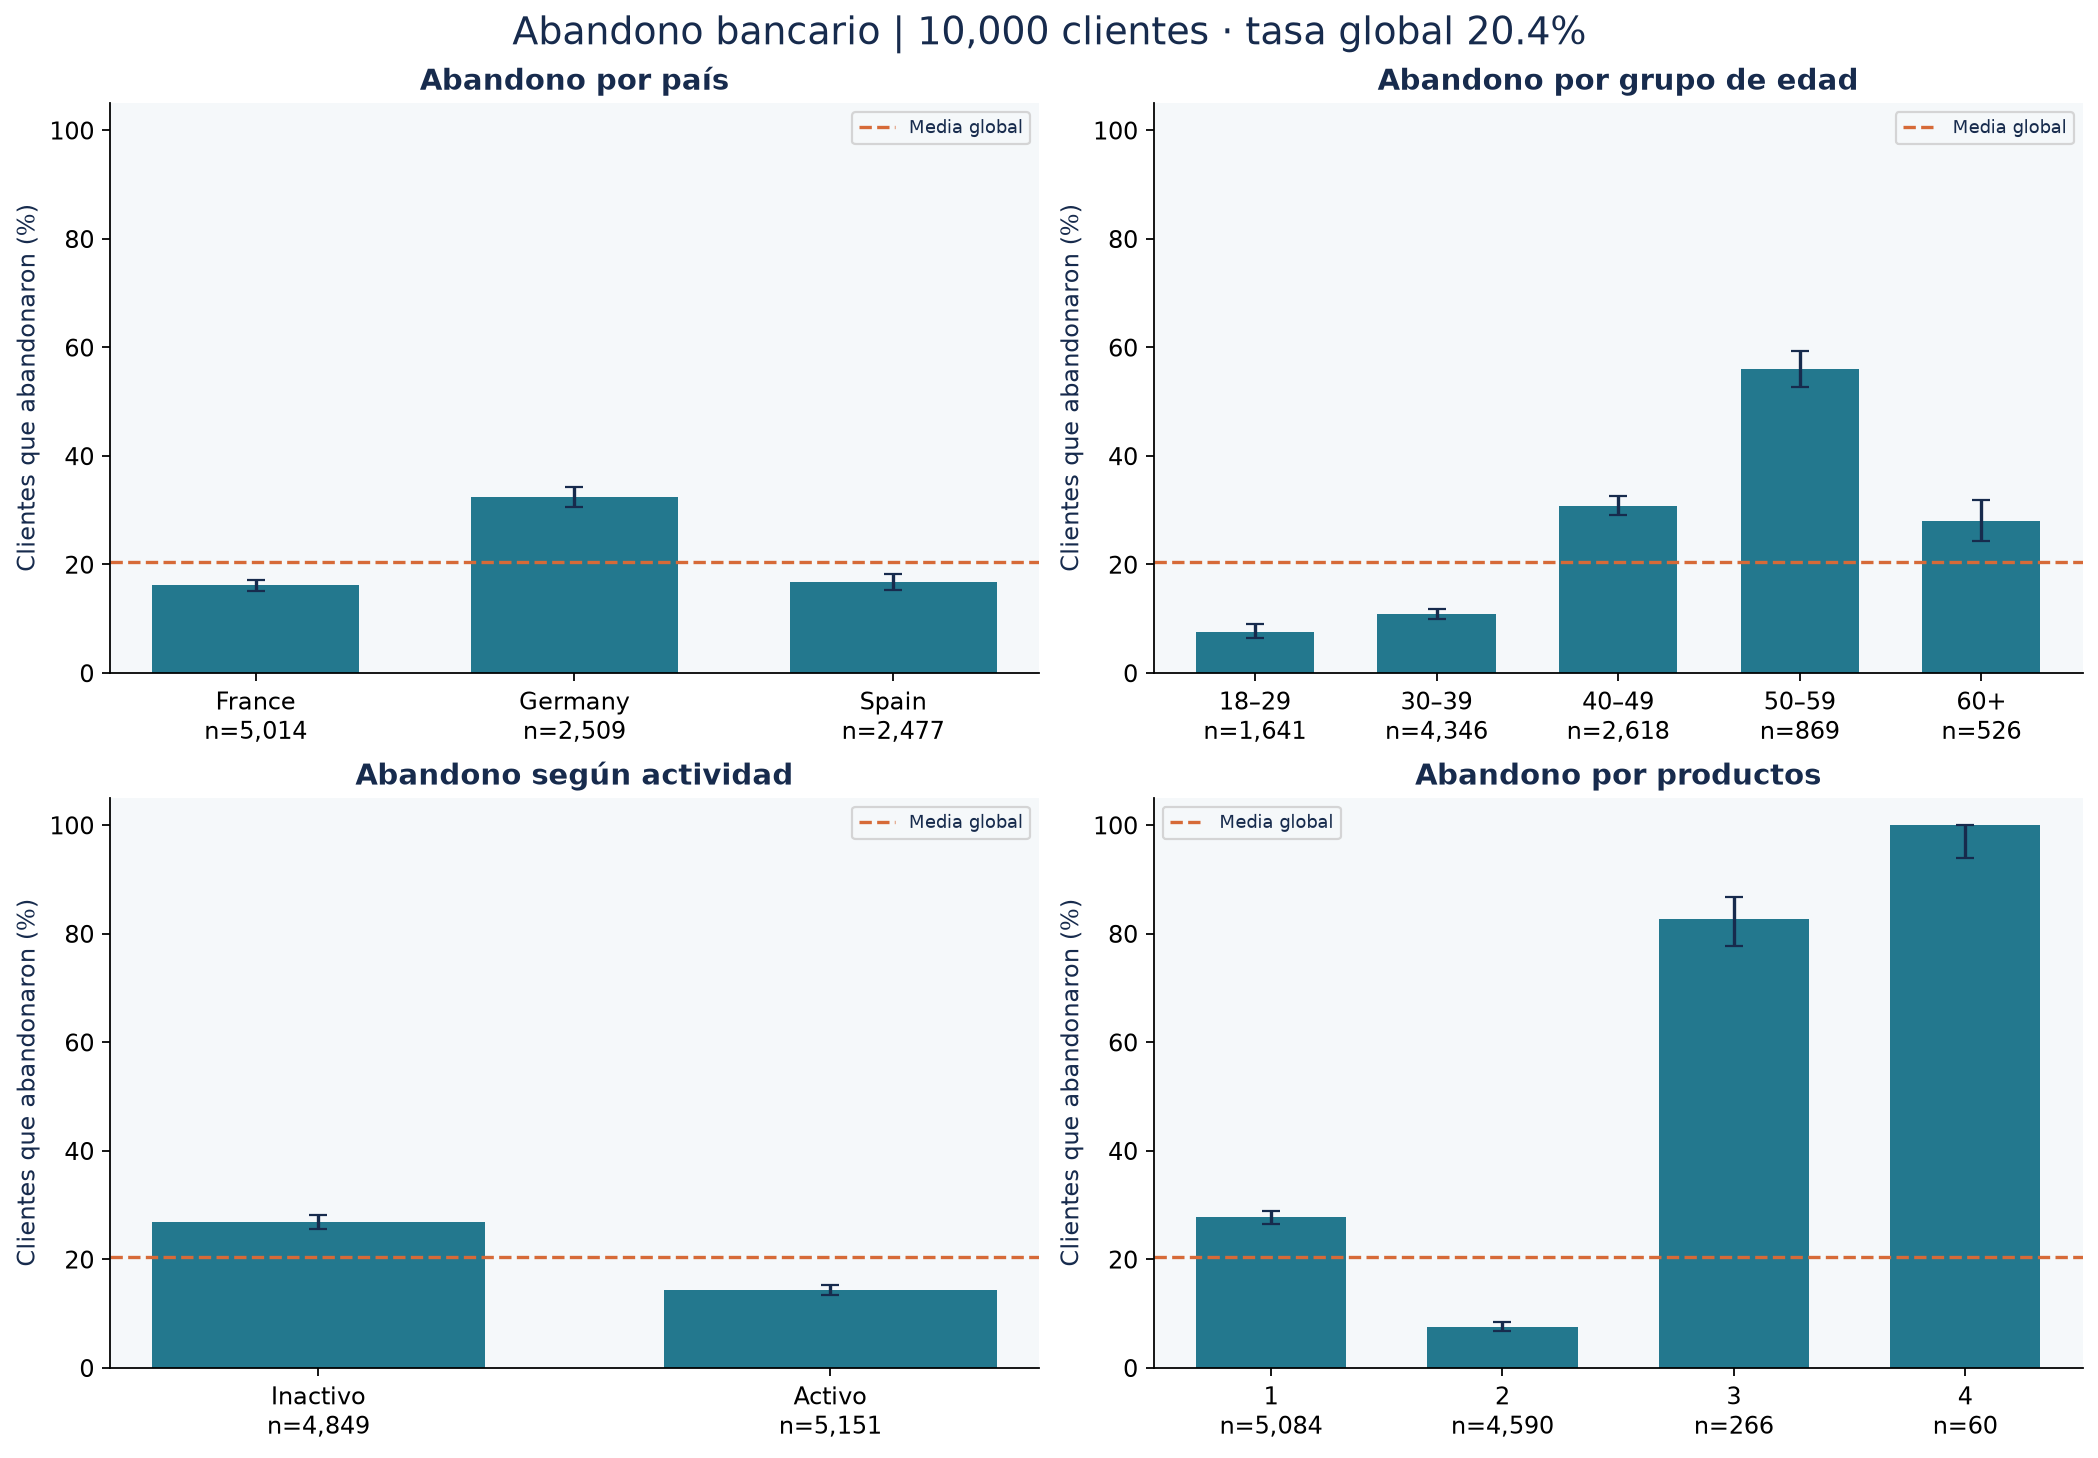

In [6]:
display(Image(filename=str(ROOT / 'reports/segmentos.png')))

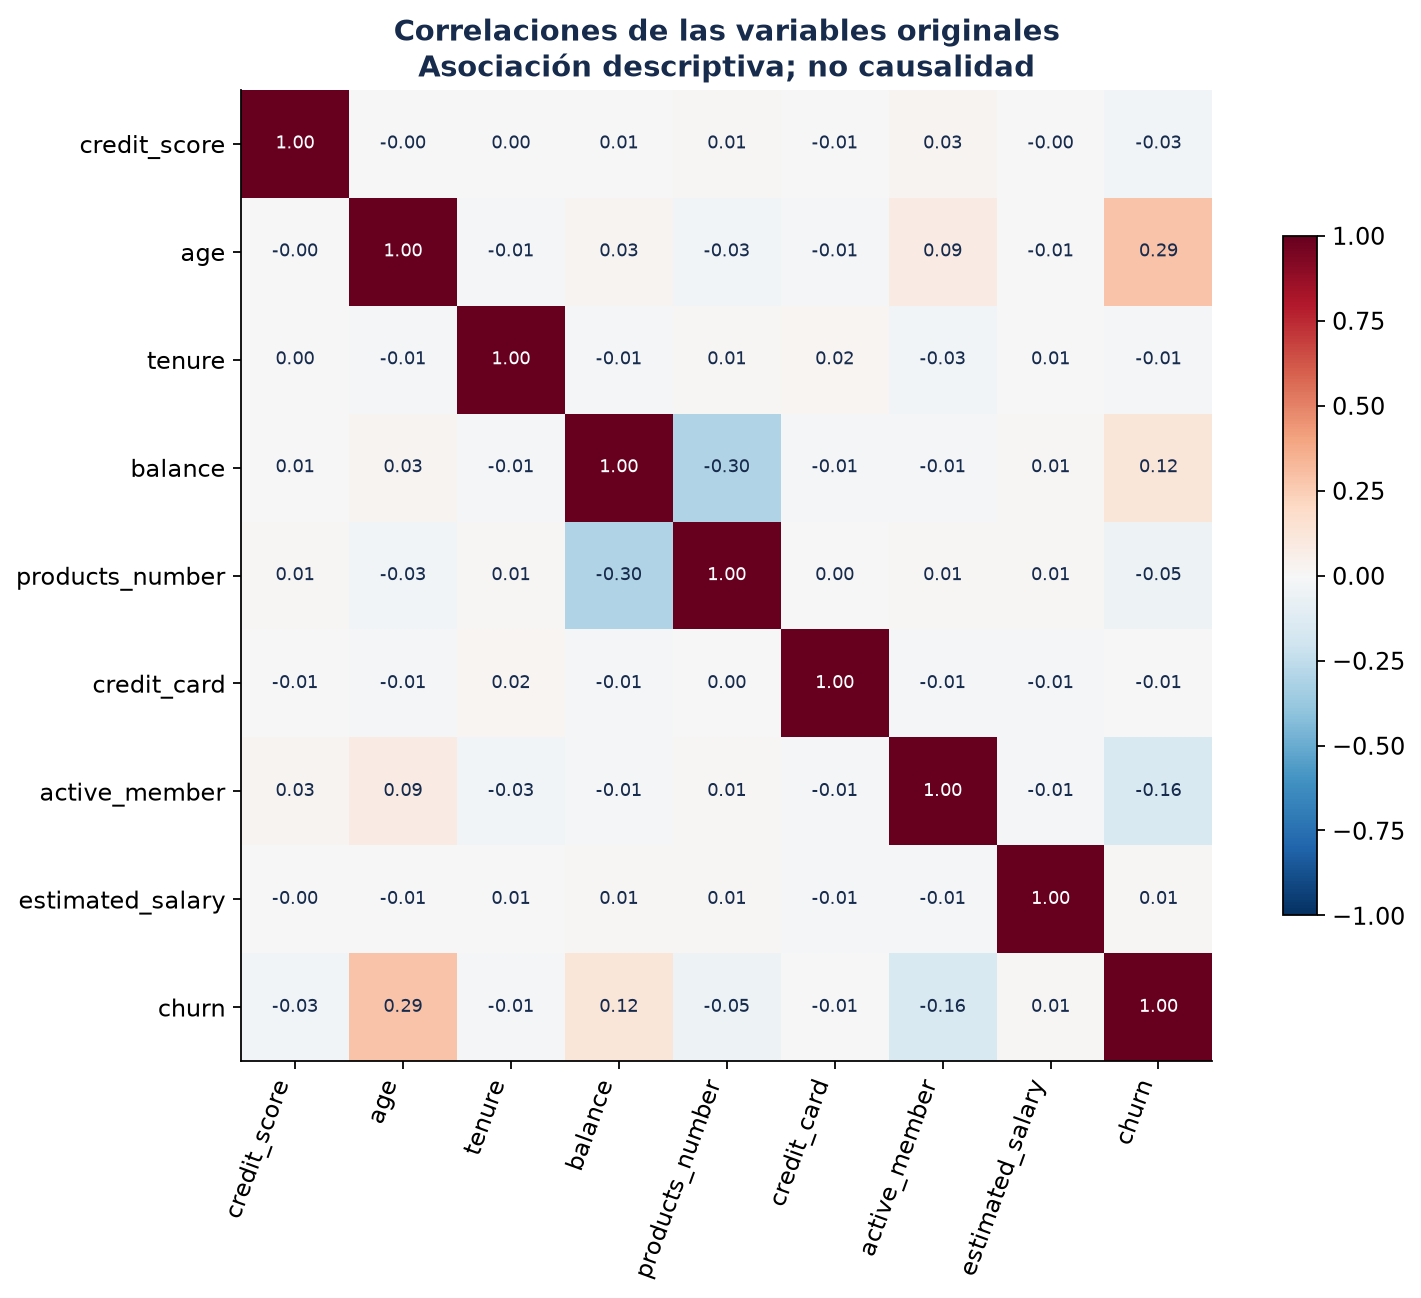

In [7]:
display(Image(filename=str(ROOT / 'reports/correlaciones.png')))

Alemania presenta una tasa de abandono mayor que Francia y España en esta muestra. La diferencia justifica investigar servicio, composición de clientes y oferta comercial antes de proponer acciones. Los grupos con tres o cuatro productos tienen tasas elevadas, pero tamaños mucho menores: 266 y 60 clientes. El grupo de cuatro productos tiene un 100 % observado, que no implica una probabilidad poblacional conocida del 100 %.

## 6. Limitaciones y próximos pasos

Los intervalos suponen observaciones independientes y no corrigen comparaciones múltiples. La muestra no acredita representatividad de un banco real. Las diferencias pueden depender de variables no observadas; país y edad no deben convertirse automáticamente en criterios de intervención. Las tablas públicas son agregadas, pero eso no constituye una garantía formal de anonimización. No se ha medido ahorro económico ni reducción real del abandono.

Antes de ampliar el uso, validar con una fuente independiente y acordar criterios de utilidad con el destinatario. Consulta el README para reproducir las pruebas y los informes.

## 7. Trazabilidad de esta ejecución

Se muestran nombres de archivos, huellas SHA-256 y versiones; las entradas completas permanecen fuera de Git.

In [8]:
fuentes = resultado.get('fuentes', [resultado.get('fuente')])
print(json.dumps(fuentes, ensure_ascii=False, indent=2))

[
  {
    "archivo": "Bank Customer Churn Prediction.csv",
    "sha256": "90f6625c31bdfcb0cde3b94c4f3004e43795e382921d0a5be67c4bd490b38818",
    "python": "3.11.9",
    "paquetes": {
      "pandas": "3.0.6",
      "numpy": "2.4.6",
      "matplotlib": "3.11.2",
      "scikit-learn": "1.9.1"
    }
  }
]


[Historial del proyecto](https://github.com/hectortorres26/analisis-abandono-bancario/commits/main) · [Comparación con el original](https://github.com/hectortorres26/analisis-abandono-bancario/compare/f527704abd53c9d7a21cb0a651236eb891b827c8...main)